<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/Support_Vector/wine_quality_svm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Support Vector Machine Project: Find the Good Wines

**Goal:** from the chemical measurements of a red wine (acidity, sugar, alcohol and so on), predict whether it is a **good wine** (expert quality score of 7 or more out of 10).

**What is a Support Vector Machine (SVM)?** Imagine the wines as points in space. An SVM draws the boundary that separates the two groups with the **widest possible margin** (gap). Only the points closest to the boundary, the **support vectors**, decide where it goes. With a **kernel** (the RBF kernel is the popular one), the boundary can bend into curves instead of being a straight line.

**What you will learn**

- Why SVMs **need feature scaling** (and what happens without it).
- The two main settings: **C** (how strict the boundary is) and **gamma** (how wiggly it is), and how to tune them.
- How to handle an **imbalanced** target (good wines are rare) with `class_weight` and a custom **threshold**.
- How to **see** a decision boundary and count the support vectors.
- How an SVM compares with logistic regression and a random forest.

**Dataset:** the Red Wine Quality data (about 1,600 wines, 11 chemical measurements and a quality score), a classic from the UCI Machine Learning Repository. It is loaded directly from a URL below, so you do not need to upload anything. Note that this file uses a **semicolon** (`;`) as its separator.

**Steps:** 1) Load, 2) Explore, 3) Target and split, 4) Why scaling matters, 5) Default models, 6) See the boundary, 7) Tune C and gamma, 8) Class weights, 9) Choose a threshold, 10) Final evaluation, 11) Support vectors, 12) Compare models, 13) Predict a new wine.

Run the cells from top to bottom (Shift + Enter).

## Step 1: Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = 'https://raw.githubusercontent.com/shrikant-temburwar/Wine-Quality-Dataset/master/winequality-red.csv'
df = pd.read_csv(url, sep=';')

print('Rows and columns:', df.shape)
df.head()

Rows and columns: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


*If this link ever stops working, the same file is available from the UCI repository (search for "Wine Quality" and download `winequality-red.csv`). Upload it to Colab and use `pd.read_csv('winequality-red.csv', sep=';')`.*

Each row is one wine. The 11 feature columns are chemical measurements, and `quality` is the score given by tasters.

## Step 2: Explore the data

In [2]:
df.info()
print()
print('Missing values:', int(df.isna().sum().sum()))
print('Fully duplicated rows:', int(df.duplicated().sum()))
print()
print('Wines per quality score:')
print(df['quality'].value_counts().sort_index().to_string())
df.describe().T.round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing values: 0
Fully duplicated rows: 240

Wines per quality score:
quality
3     10
4     53
5    681
6    638
7    199
8

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.32,1.74,4.60,7.10,7.90,9.20,15.90
volatile acidity,1599.0,0.53,0.18,0.12,0.39,0.52,0.64,1.58
citric acid,1599.0,0.27,0.19,0.00,0.09,0.26,0.42,1.00
residual sugar,1599.0,2.54,1.41,0.90,1.90,2.20,2.60,15.50
chlorides,1599.0,0.09,0.05,0.01,0.07,0.08,0.09,0.61
free sulfur dioxide,1599.0,15.87,10.46,1.00,7.00,14.00,21.00,72.00
total sulfur dioxide,1599.0,46.47,32.90,6.00,22.00,38.00,62.00,289.00
density,1599.0,1.00,0.00,0.99,1.00,1.00,1.00,1.00
pH,1599.0,3.31,0.15,2.74,3.21,3.31,3.40,4.01
sulphates,1599.0,0.66,0.17,0.33,0.55,0.62,0.73,2.00


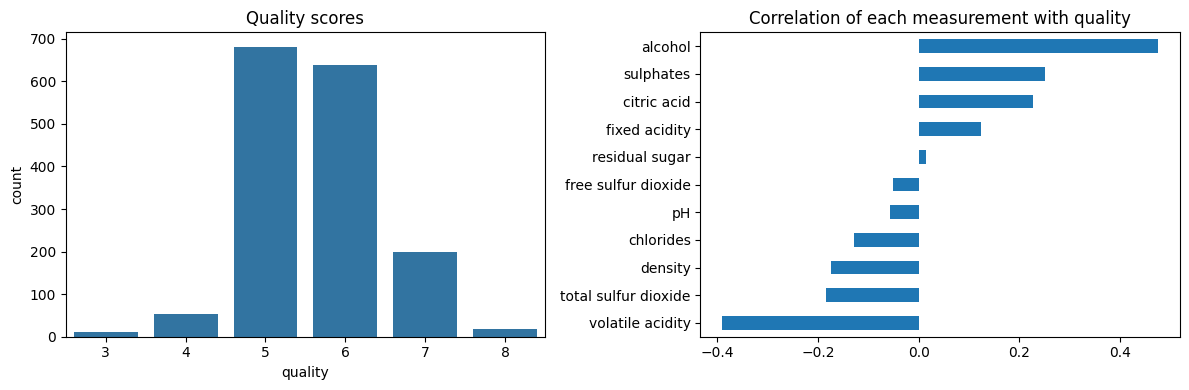

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='quality', data=df, ax=axes[0])
axes[0].set_title('Quality scores')
corr = df.corr()['quality'].drop('quality').sort_values()
corr.plot.barh(ax=axes[1])
axes[1].set_title('Correlation of each measurement with quality')
plt.tight_layout()
plt.show()

**What to notice:**
- Most wines score 5 or 6. Very few score 7 or higher, so "good wine" will be a **rare class**.
- Some rows are exact duplicates. If a duplicate lands in both the training and the test set, the model gets to "see" test answers during training, so we remove them before splitting.
- The columns are on very **different scales** (`total sulfur dioxide` goes into the hundreds while `chlorides` is around 0.1). That matters a lot for SVMs, as we will see in Step 4.
- Alcohol and volatile acidity show the strongest links with quality (look at the bar chart).

## Step 3: Define the target and split the data

We turn the score into a yes/no question: `good = 1` if the quality is **7 or more**, otherwise `0`. We drop duplicate rows first, then keep 25% of the wines aside as a **test set**. `stratify=y` keeps the share of good wines the same in both parts.

In [4]:
from sklearn.model_selection import train_test_split

df = df.drop_duplicates().reset_index(drop=True)
df['good'] = (df['quality'] >= 7).astype(int)

X = df.drop(columns=['quality', 'good'])
y = df['good']

print('Wines after removing duplicates:', len(df))
print('Share of good wines: {:.1%}'.format(y.mean()))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print('Training wines:', len(X_train), '| Test wines:', len(X_test))
print('Good wines in training: {:.1%} | in test: {:.1%}'.format(y_train.mean(), y_test.mean()))

Wines after removing duplicates: 1359
Share of good wines: 13.5%
Training wines: 1019 | Test wines: 340
Good wines in training: 13.5% | in test: 13.5%


**Why accuracy is not enough here:** if only about one wine in six or seven is good, a model that **always says "not good"** is right most of the time and yet finds no good wine at all. So besides accuracy we will look at **precision**, **recall**, **F1** and **ROC-AUC**, and we compare every model against that lazy baseline.

## Step 4: Why scaling matters for SVMs

An SVM measures **distances** between wines. If one column has numbers in the hundreds and another has numbers around 0.1, the big column dominates the distance and the small one is practically ignored. `StandardScaler` rescales every column to a mean of 0 and a spread of 1. Let us compare the same SVM with and without it.

We use a **pipeline**, so the scaler learns its numbers only from the training part of each cross-validation fold (this avoids leaking information from the validation data).

In [5]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'f1': 'f1', 'roc_auc': 'roc_auc'}


def cv_report(model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    return {k: r['test_' + k].mean() for k in scoring}


rows = []
for name, model in {
    'SVM (RBF) WITHOUT scaling': SVC(kernel='rbf'),
    'SVM (RBF) WITH scaling': make_pipeline(StandardScaler(), SVC(kernel='rbf')),
}.items():
    rows.append({'model': name, **cv_report(model)})

print(pd.DataFrame(rows).round(3).to_string(index=False))

                    model  accuracy    f1  roc_auc
SVM (RBF) WITHOUT scaling     0.867 0.028    0.822
   SVM (RBF) WITH scaling     0.888 0.412    0.835


**How to read this:** compare the two rows, especially **F1** and **ROC-AUC**. Without scaling, the SVM mostly listens to the columns with the biggest numbers. Scaling lets all 11 measurements contribute, and it usually improves the results clearly. **Rule: always scale your features before an SVM** (and before KNN and logistic regression too).

## Step 5: Default models side by side

We compare the lazy baseline, logistic regression, a linear SVM and an RBF SVM, all with default settings and scaling, using cross-validation on the training set only.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

default_models = {
    'Baseline (always "not good")': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'SVM, linear kernel': make_pipeline(StandardScaler(), SVC(kernel='linear')),
    'SVM, RBF kernel': make_pipeline(StandardScaler(), SVC(kernel='rbf')),
}

rows = []
for name, model in default_models.items():
    rows.append({'model': name, **cv_report(model)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                       model  accuracy    f1  roc_auc
Baseline (always "not good")     0.865 0.000    0.500
         Logistic regression     0.874 0.398    0.873
          SVM, linear kernel     0.865 0.000    0.845
             SVM, RBF kernel     0.888 0.412    0.835


**What to look for:** the baseline has a decent accuracy but an **F1 of 0**, because it never finds a good wine. That is exactly why we look at more than accuracy. Then compare the linear and RBF kernels: a linear SVM can only draw a straight boundary, while the RBF kernel can curve it, which helps when the groups are not separable by a straight line.

## Step 6: See the decision boundary

To draw a picture we need two features, so we use only `alcohol` and `volatile acidity` here. This is just for understanding. The plots show how **C** and **gamma** change the boundary of an RBF SVM:

- **C** is the price of a mistake. Small C gives a smooth, tolerant boundary. Large C tries hard to classify every training point correctly, even if the boundary becomes twisted.
- **gamma** is the reach of each point. Small gamma means each point influences far away (smooth boundary). Large gamma means only very close neighbours matter (a boundary that wraps around single points, which is overfitting).

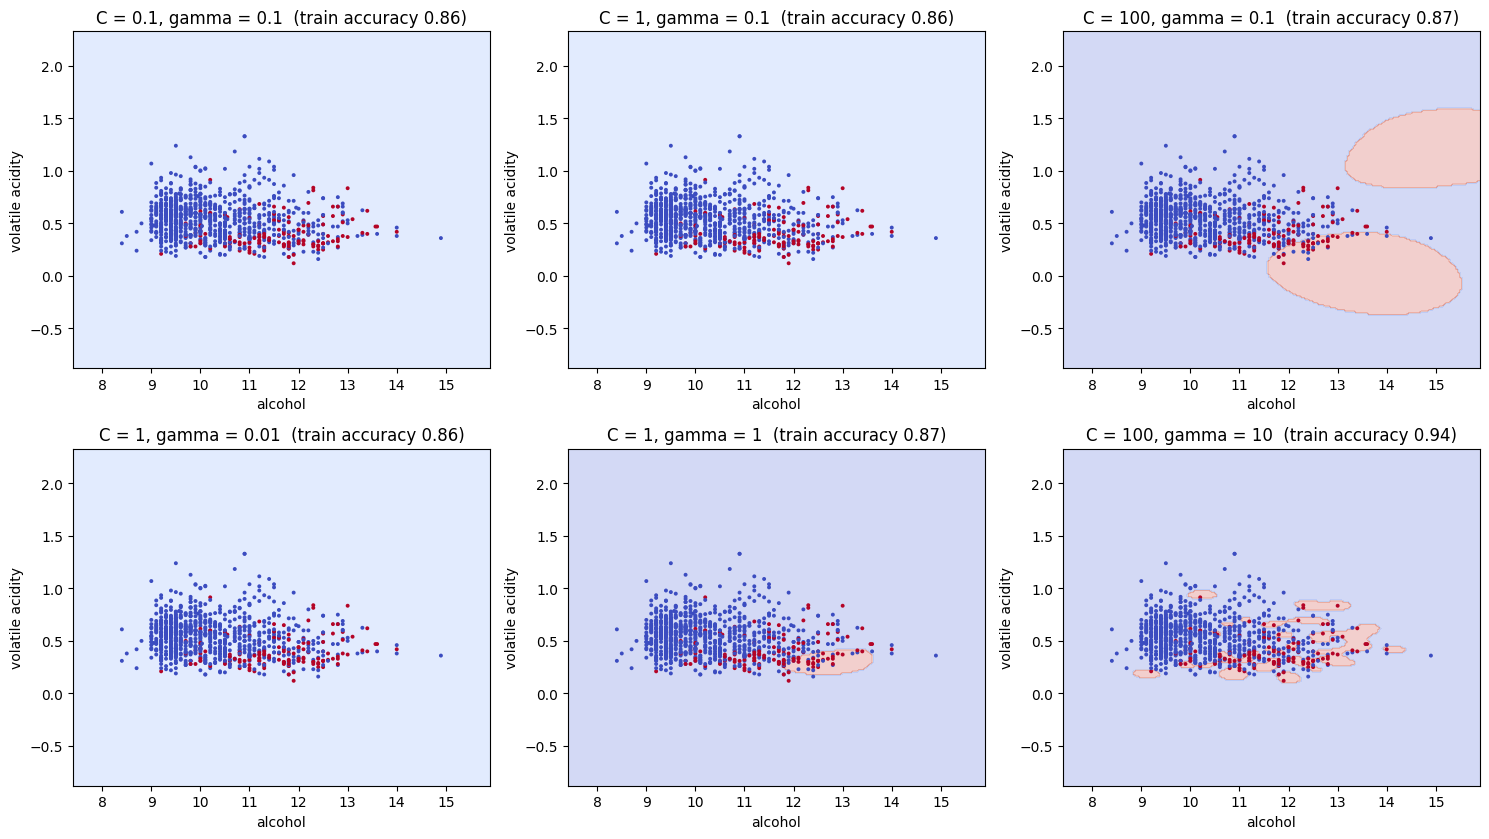

In [7]:
from sklearn.inspection import DecisionBoundaryDisplay

two = ['alcohol', 'volatile acidity']
X2 = X_train[two]

settings = [(0.1, 0.1), (1, 0.1), (100, 0.1),
            (1, 0.01), (1, 1), (100, 10)]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, (C, gamma) in zip(axes.ravel(), settings):
    m = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=C, gamma=gamma)).fit(X2, y_train)
    DecisionBoundaryDisplay.from_estimator(m, X2, response_method='predict', alpha=0.25,
                                           cmap='coolwarm', ax=ax, grid_resolution=200, xlabel=two[0], ylabel=two[1])
    ax.scatter(X2[two[0]], X2[two[1]], c=y_train, cmap='coolwarm', s=8, edgecolor='none')
    ax.set_title(f'C = {C}, gamma = {gamma}  (train accuracy {m.score(X2, y_train):.2f})')
plt.tight_layout()
plt.show()

**What to notice:** compare the panels. With small `C` and `gamma` the boundary is very smooth and may miss most of the (red) good wines. As `C` and `gamma` grow, the boundary starts to bend around individual points, and the training accuracy climbs, but that does not mean it will do better on new wines. The best values are somewhere in between, so we find them with a search.

## Step 7: Tune C and gamma

We try many combinations of `C` and `gamma` with **GridSearchCV** (5-fold cross-validation on the training data). We score with **average precision**, which measures how well the model **ranks** good wines above the others and works well for a rare class. The test set stays untouched.

Best settings: {'svc__C': 1, 'svc__gamma': 0.3}
Best cross-validated average precision: 0.572


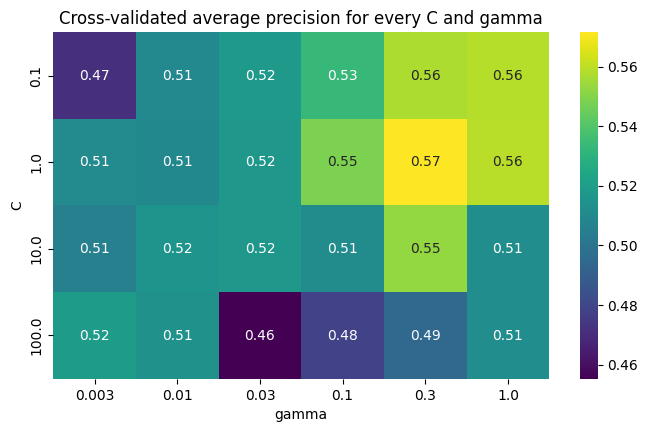

In [8]:
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(StandardScaler(), SVC(kernel='rbf'))
param_grid = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': [0.003, 0.01, 0.03, 0.1, 0.3, 1],
}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring='average_precision', n_jobs=-1)
grid.fit(X_train, y_train)

print('Best settings:', grid.best_params_)
print('Best cross-validated average precision:', round(grid.best_score_, 3))

# heatmap of all the combinations
scores = pd.DataFrame(grid.cv_results_)
heat = scores.pivot(index='param_svc__C', columns='param_svc__gamma', values='mean_test_score').astype(float)
plt.figure(figsize=(8, 4.5))
sns.heatmap(heat, annot=True, fmt='.2f', cmap='viridis')
plt.title('Cross-validated average precision for every C and gamma')
plt.xlabel('gamma')
plt.ylabel('C')
plt.show()

**How to read the heatmap:** each cell is one combination, and brighter is better. Usually there is a good "valley", with poor results at both extremes (too smooth or too wiggly). If the best cell is on the **edge** of the grid, extend the grid in that direction and search again. That is a good exercise.

## Step 8: Class weights for the rare class

By default an SVM treats every mistake equally, so with a rare class it may sacrifice the good wines to keep the overall error low. `class_weight='balanced'` makes a mistake on a good wine count **more**, in proportion to how rare they are. We tune again with it and compare.

In [9]:
pipe_bal = make_pipeline(StandardScaler(), SVC(kernel='rbf', class_weight='balanced'))
grid_bal = GridSearchCV(pipe_bal, param_grid, cv=cv, scoring='average_precision', n_jobs=-1)
grid_bal.fit(X_train, y_train)

print('Balanced best settings:', grid_bal.best_params_)

rows = []
for name, g in {'Tuned SVM': grid, 'Tuned SVM + class_weight=balanced': grid_bal}.items():
    r = cross_validate(g.best_estimator_, X_train, y_train, cv=cv,
                       scoring={'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'})
    rows.append({'model': name, **{k: r['test_' + k].mean() for k in ['precision', 'recall', 'f1', 'roc_auc']}})
print()
print(pd.DataFrame(rows).round(3).to_string(index=False))

Balanced best settings: {'svc__C': 1, 'svc__gamma': 0.3}

                            model  precision  recall    f1  roc_auc
                        Tuned SVM      0.729   0.283 0.403    0.836
Tuned SVM + class_weight=balanced      0.466   0.623 0.532    0.870


**What to look for:** compare **precision** and **recall**. The balanced version usually finds **more** of the good wines (higher recall) but also raises more false alarms (lower precision). Neither is "right": it is a trade-off. Which is better depends on the goal. Maybe you want to find nearly all the good wines for a tasting (favor recall), or maybe you only want to recommend wines you are very sure about (favor precision).

## Step 9: Choose a threshold

An SVM gives each wine a **score** (`decision_function`): positive means "good", negative means "not good", and the further from 0 the more confident. The default cut-off is 0, but we can move it. We pick the threshold that gives the best **F1** using **cross-validated scores on the training data** (so the test set stays untouched), and then we choose between the two models using the same cross-validated numbers.

In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, f1_score


def best_threshold(model):
    s = cross_val_predict(model, X_train, y_train, cv=cv, method='decision_function')
    prec, rec, thr = precision_recall_curve(y_train, s)
    f1 = np.nan_to_num(2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1]))
    i = int(np.argmax(f1))
    return float(thr[i]), float(f1[i]), f1_score(y_train, (s >= 0).astype(int))


results = {}
for name, g in {'Tuned SVM': grid, 'Tuned SVM + balanced': grid_bal}.items():
    thr, f1_best, f1_default = best_threshold(g.best_estimator_)
    results[name] = (thr, f1_best)
    print(f'{name:<22} default threshold (0) F1: {f1_default:.3f} | best threshold {thr:+.2f} gives F1: {f1_best:.3f}')

best_name = max(results, key=lambda k: results[k][1])
final_model = {'Tuned SVM': grid, 'Tuned SVM + balanced': grid_bal}[best_name].best_estimator_
final_threshold = results[best_name][0]
print()
print('Chosen model:', best_name, '| threshold:', round(final_threshold, 2))

Tuned SVM              default threshold (0) F1: 0.404 | best threshold -0.78 gives F1: 0.541
Tuned SVM + balanced   default threshold (0) F1: 0.531 | best threshold +0.31 gives F1: 0.536

Chosen model: Tuned SVM | threshold: -0.78


**What this means:** moving the threshold lets you trade precision for recall **without retraining**. A lower threshold labels more wines as good (more recall, less precision); a higher threshold does the opposite. The score is only a ranking, not a probability.

## Step 10: Final evaluation on the test set

This is the first time the **test set** is used to judge the chosen model.

Test ROC-AUC          : 0.837
Test average precision: 0.549

----- default threshold (0)
              precision    recall  f1-score   support

    not good      0.903     0.980     0.940       294
        good      0.714     0.326     0.448        46

    accuracy                          0.891       340
   macro avg      0.809     0.653     0.694       340
weighted avg      0.877     0.891     0.873       340

----- chosen threshold (-0.78)
              precision    recall  f1-score   support

    not good      0.936     0.895     0.915       294
        good      0.475     0.609     0.533        46

    accuracy                          0.856       340
   macro avg      0.705     0.752     0.724       340
weighted avg      0.874     0.856     0.863       340



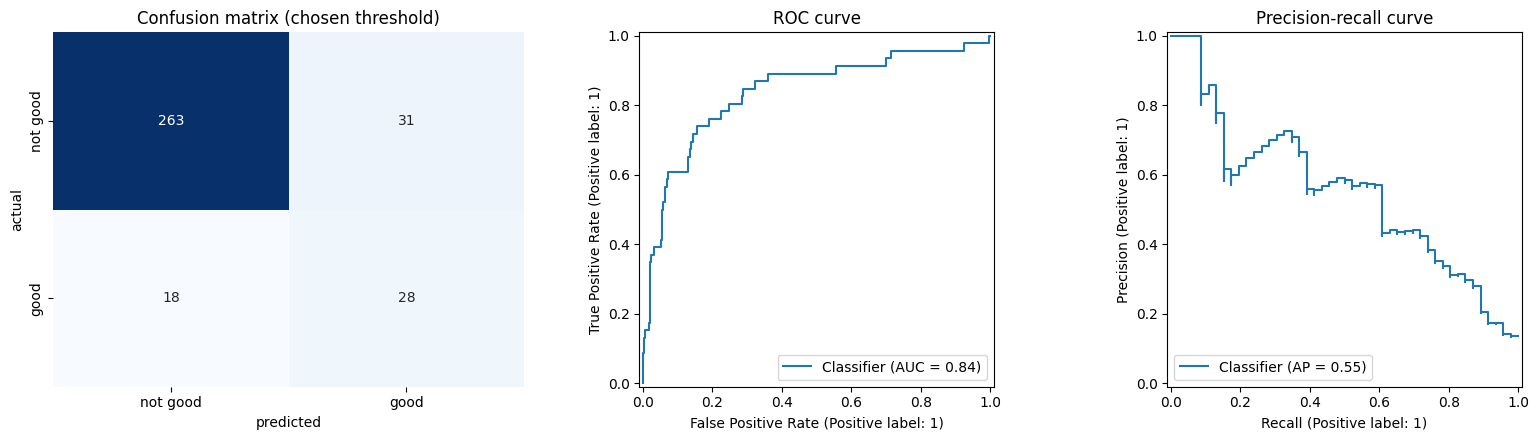

In [11]:
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             average_precision_score, RocCurveDisplay, PrecisionRecallDisplay)

final_model.fit(X_train, y_train)
test_scores = final_model.decision_function(X_test)
pred_default = (test_scores >= 0).astype(int)
pred_tuned = (test_scores >= final_threshold).astype(int)

print('Test ROC-AUC          :', round(roc_auc_score(y_test, test_scores), 3))
print('Test average precision:', round(average_precision_score(y_test, test_scores), 3))
print()
for label, pred in [('default threshold (0)', pred_default), (f'chosen threshold ({final_threshold:+.2f})', pred_tuned)]:
    print('-----', label)
    print(classification_report(y_test, pred, target_names=['not good', 'good'], digits=3))

cm = confusion_matrix(y_test, pred_tuned)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['not good', 'good'], yticklabels=['not good', 'good'])
axes[0].set_xlabel('predicted')
axes[0].set_ylabel('actual')
axes[0].set_title('Confusion matrix (chosen threshold)')
RocCurveDisplay.from_predictions(y_test, test_scores, ax=axes[1])
axes[1].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(y_test, test_scores, ax=axes[2])
axes[2].set_title('Precision-recall curve')
plt.tight_layout()
plt.show()

**How to read this:**
- **ROC-AUC** is the chance that a random good wine gets a higher score than a random not-good wine (0.5 is guessing, 1.0 is perfect).
- In the confusion matrix, the bottom-right number is good wines found, the bottom-left is good wines **missed**, and the top-right is false alarms.
- The test set is small and has only a modest number of good wines, so the numbers can move by a few points with a different split. Do not read too much into small differences.

## Step 11: What are the support vectors?

Only the **support vectors** (the points closest to, or on the wrong side of, the boundary) define the SVM. All other points could be removed without changing the model. Let us count them.

In [12]:
svc = final_model.named_steps['svc']
n_sv = svc.n_support_
print('Training wines:', len(X_train))
print('Support vectors for "not good" wines:', n_sv[0])
print('Support vectors for "good" wines    :', n_sv[1])
print('Share of training wines that are support vectors: {:.0%}'.format(n_sv.sum() / len(X_train)))

Training wines: 1019
Support vectors for "not good" wines: 333
Support vectors for "good" wines    : 127
Share of training wines that are support vectors: 45%


**What to notice:** when the classes overlap a lot, as they do with wine quality, a large share of the training points end up as support vectors. A model with many support vectors is slower to predict, and it hints that the boundary between the groups is not clean.

## Step 12: Compare with other models

How does the tuned SVM compare with logistic regression and a random forest on the **same test set**? We use ROC-AUC and average precision, which do not depend on a threshold.

In [13]:
from sklearn.ensemble import RandomForestClassifier

others = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
    'Random forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1),
    'Tuned SVM (' + best_name + ')': final_model,
}

rows = []
for name, m in others.items():
    m.fit(X_train, y_train)
    s = m.decision_function(X_test) if hasattr(m, 'decision_function') else m.predict_proba(X_test)[:, 1]
    rows.append({'model': name, 'ROC-AUC': roc_auc_score(y_test, s), 'average precision': average_precision_score(y_test, s)})

print(pd.DataFrame(rows).round(3).to_string(index=False))

                model  ROC-AUC  average precision
  Logistic regression    0.876              0.529
        Random forest    0.867              0.518
Tuned SVM (Tuned SVM)    0.837              0.549


**What to expect:** on a data set like this, a tuned SVM is usually competitive with the others, and a random forest is often the strongest. The SVM is not guaranteed to win: the best model depends on the data. That is why we always compare against simple baselines and other algorithms.

## Step 13: Predict a new wine

Enter the measurements of a wine (the columns must be in the same order and units as the data) and get the score and the verdict.

In [14]:
new_wine = pd.DataFrame([{
    'fixed acidity': 7.5, 'volatile acidity': 0.35, 'citric acid': 0.40, 'residual sugar': 2.2,
    'chlorides': 0.065, 'free sulfur dioxide': 12, 'total sulfur dioxide': 35, 'density': 0.9945,
    'pH': 3.25, 'sulphates': 0.80, 'alcohol': 12.0,
}])[X.columns]

score = final_model.decision_function(new_wine)[0]
print(f'Score: {score:+.2f}  (threshold {final_threshold:+.2f})')
print('Verdict:', 'GOOD wine' if score >= final_threshold else 'not a good wine')

# For comparison, the typical wine in the data set
print()
print('Typical (median) wine for reference:')
print(X.median().round(3).to_string())

Score: +1.20  (threshold -0.78)
Verdict: GOOD wine

Typical (median) wine for reference:
fixed acidity            7.900
volatile acidity         0.520
citric acid              0.260
residual sugar           2.200
chlorides                0.079
free sulfur dioxide     14.000
total sulfur dioxide    38.000
density                  0.997
pH                       3.310
sulphates                0.620
alcohol                 10.200


**Try it:** change `alcohol`, `volatile acidity` and `sulphates` and watch the score move. Higher alcohol and lower volatile acidity usually push a wine toward "good". Remember that the model only knows chemistry; it has never tasted a wine.

## Practice ideas

1. In Step 7, extend the grid (for example `C` up to 1000, `gamma` down to 0.0003) and see if the best score improves.
2. Try `kernel='poly'` and `kernel='linear'` with their own settings, and compare them with RBF.
3. Change the target to `quality >= 6` (a much more balanced problem) and see how every number changes.
4. Use `SVR` (the regression version of SVM) to predict the actual quality score, and measure it with MAE and R².
5. Try the **white wine** data set (`winequality-white.csv`) with the same notebook.
6. Remove one feature at a time and see which ones the SVM really needs. (Hint: `permutation_importance` works with any model.)